# Växjö route 1: delay along recurring journeys

Complete September 2026; weekday, direction-0 Löparvägen–Kurortsvägen pattern.
Regional buses and other route 1 patterns are kept separate.

**Finding:** recorded delay repeatedly increases between Stortorget and Dalbo.
The pooled median increase is 124 seconds across 1,338 pairs (99.63% coverage).
All 22 weekday medians and all 60 reportable recurring-departure medians are positive.
The 15:23 departure gains delay on all 22 observed dates, with a median increase
of 223 seconds. The cause remains unestablished.

Dalbo is the last non-final timing stop: recovery after it cannot be established
with the primary population. See `docs/city-route1-study.md` for interpretation
and the measurement boundary.

## 1. Verify and reproduce the evidence

The analysis checks the 180-file SHA-256 manifest for the pinned warehouse revision
`3cb190163d9c400fd915bd62a919f8f9bfc90dd7`, uses the existing route category, and
recomputes stored delays from retained timestamps. No credentials or live writes.
Prepare the snapshot with `scripts/prepare_case_study.py` first; plotting requires
Matplotlib and a Python notebook kernel.

In [1]:
import json
import runpy
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
assert (ROOT / "scripts" / "analyze_city_route1.py").exists()
runpy.run_path(str(ROOT / "scripts" / "analyze_city_route1.py"), run_name="__main__")
OUTPUT = ROOT / "data" / "case-study" / "city-route1"
evidence = json.loads((OUTPUT / "evidence.json").read_text(encoding="utf-8"))
results = {name: item["rows"] for name, item in evidence["results"].items()}
print("Revision:", evidence["revision"])
print("Executed:", evidence["executed_at"])
print("Checks:", evidence["checks"])

scope: 1 rows
route_population: 1 rows
pattern_inventory: 12 rows
section_summary: 3 rows
recurring_section: 64 rows
section_hour: 21 rows
section_dates: 22 rows
individual_pairs: 1354 rows
individual_journeys: 5416 rows
afternoon_sections: 3 rows
linked_recovery: 2 rows
selected_departure_stops: 8 rows
leave_one_date_out: 22 rows


Route 1 checks passed.
Revision: 3cb190163d9c400fd915bd62a919f8f9bfc90dd7
Executed: 2026-10-11T15:45:05.965387+00:00
Checks: Snapshot hashes, source-key uniqueness, dates, category, joined/raw eligibility, timestamp delays, recurring-to-section counts and paired arithmetic passed.


## 2. Compare adjacent timing-stop sections

Paired change is later recorded delay minus earlier recorded delay within the same
date/trip. Pairs are constructed before eligibility filtering, so missing or
ineligible timing stops cannot be silently bridged. Coverage requires both ends.
On time remains −60 to +180 seconds inclusive; final stops are excluded.

stop_name | next_stop_name | observed_pairs | eligible_pairs | coverage_pct | median_change | gained_delay
Löparvägen | Teleborg C | 1332 | 1342 | 99.25 | 25.0 | 900
Teleborg C | Stortorget | 1336 | 1339 | 99.78 | -23.0 | 406
Stortorget | Dalbo Centrum | 1338 | 1343 | 99.63 | 124.0 | 1289


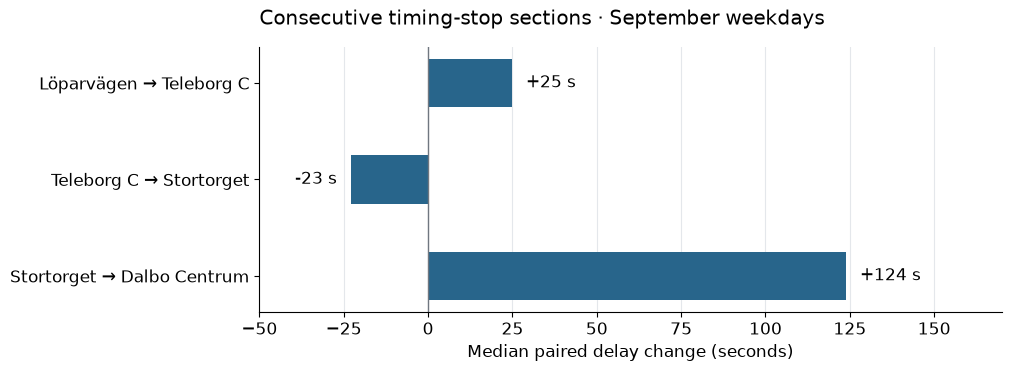

In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
BLUE, ORANGE, GREY = "#28658b", "#b65f25", "#707780"


def table(rows, fields):
    print(" | ".join(fields))
    for row in rows:
        print(" | ".join(str(row[field]) for field in fields))


def show(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


sections = results["section_summary"]
table(
    sections,
    [
        "stop_name",
        "next_stop_name",
        "observed_pairs",
        "eligible_pairs",
        "coverage_pct",
        "median_change",
        "gained_delay",
    ],
)
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
y = np.arange(len(sections))
ax.barh(y, [r["median_change"] for r in sections], color=BLUE, height=0.5)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(y, [r["stop_name"] + " → " + r["next_stop_name"] for r in sections])
ax.invert_yaxis()
ax.set_xlim(-50, 170)
ax.set_xlabel("Median paired delay change (seconds)")
ax.set_title("Consecutive timing-stop sections · September weekdays", loc="left", pad=16)
for i, row in enumerate(sections):
    ax.text(
        row["median_change"] + (4 if row["median_change"] >= 0 else -4),
        i,
        f"{row['median_change']:+g} s",
        va="center",
        ha="left" if row["median_change"] >= 0 else "right",
    )
ax.grid(axis="x", color="#e4e7eb")
ax.set_axisbelow(True)
show(fig, "section-changes")

The preceding Teleborg–Stortorget section typically reduces delay; Stortorget–Dalbo
usually adds it. Different sections can have different paired observation sets.
Within the 358 afternoon journeys observed at all three of those timing stops,
225 reduced delay before Stortorget and gained it again by Dalbo.

## 3. Compare recurring scheduled departures

Hold direction, full stop sequence, timing-stop flags and running-time pattern fixed.
Use start time at Löparvägen, not time at Stortorget. Show all 60 reportable groups.
Four groups fail the 20-trip floor: 16:53, 24:33, 25:33 and 26:33. Their summaries
remain in the private evidence but are withheld from the chart. The whiskers show
the 10th–90th percentiles of observed changes, not confidence intervals.

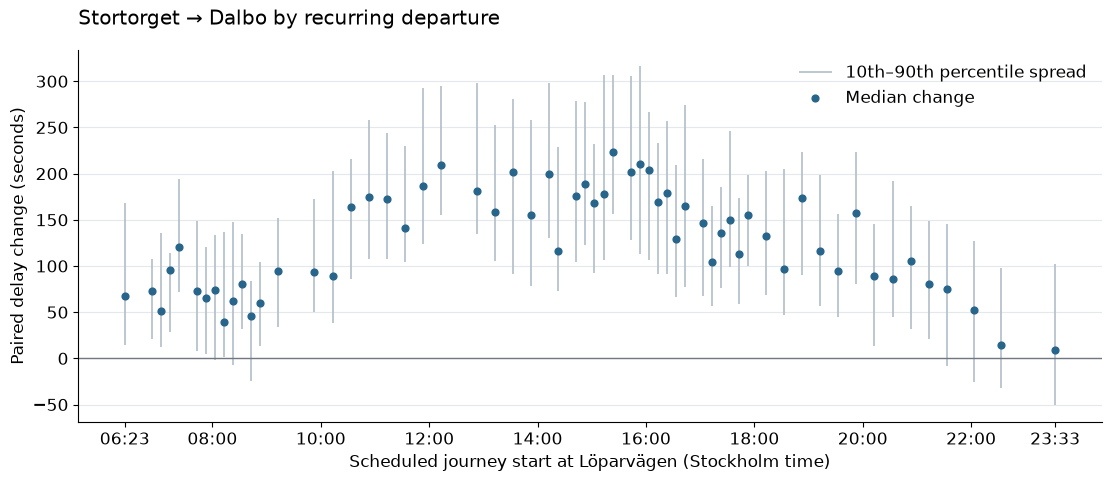

start | observed_pairs | coverage_pct | median_change | gained_delay | upstream_ontime | downstream_ontime
12:13 | 22 | 100.0 | 209.0 | 22 | 16 | 2
15:23 | 22 | 100.0 | 223.0 | 22 | 20 | 1
15:53 | 21 | 100.0 | 210.0 | 21 | 9 | 2
16:03 | 22 | 100.0 | 204.0 | 22 | 16 | 3
22:33 | 22 | 100.0 | 14.5 | 14 | 22 | 19
23:33 | 22 | 100.0 | 9.0 | 13 | 22 | 21


In [3]:
recurring = results["recurring_section"]
good = [r for r in recurring if r["reportable"]]
assert len(good) == 60
assert all(r["median_change"] > 0 for r in good)


def clock(seconds):
    return f"{seconds // 3600:02}:{seconds // 60 % 60:02}"


fig, ax = plt.subplots(figsize=(11, 4.7), layout="constrained")
x = np.array([r["start_seconds"] / 3600 for r in good])
med = np.array([r["median_change"] for r in good])
ax.vlines(
    x,
    [r["p10_change"] for r in good],
    [r["p90_change"] for r in good],
    color="#b6c3cc",
    linewidth=1.3,
    label="10th–90th percentile spread",
)
ax.scatter(x, med, color=BLUE, s=24, label="Median change", zorder=3)
ax.axhline(0, color=GREY, linewidth=1)
ticks = [x[0], 8, 10, 12, 14, 16, 18, 20, 22, x[-1]]
ax.set_xticks(ticks, [clock(round(t * 3600)) for t in ticks])
ax.set_xlabel("Scheduled journey start at Löparvägen (Stockholm time)")
ax.set_ylabel("Paired delay change (seconds)")
ax.set_title("Stortorget → Dalbo by recurring departure", loc="left", pad=18)
ax.grid(axis="y", color="#e4e7eb")
ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=False)
show(fig, "recurring-departures")
selected = [r for r in good if r["start_seconds"] in [43980, 55380, 57180, 57780, 81180, 84780]]
table(
    [{**r, "start": clock(r["start_seconds"])} for r in selected],
    [
        "start",
        "observed_pairs",
        "coverage_pct",
        "median_change",
        "gained_delay",
        "upstream_ontime",
        "downstream_ontime",
    ],
)

The gain is smaller late in the evening. Even then, a positive delay change need
not mean the departure becomes late. The comparisons are descriptive, selected
September services; they do not isolate traffic or operational effects.

## 4. Follow the 15:23 departure on individual dates

This example has observations at all four timing stops on all 22 weekdays.
Faint lines show individual service dates; the orange line is a separate median
at each stop, not an actual journey. The shaded band is the fixed on-time range.
At Stortorget 20/22 were on time; at Dalbo only 1/22 was on time.

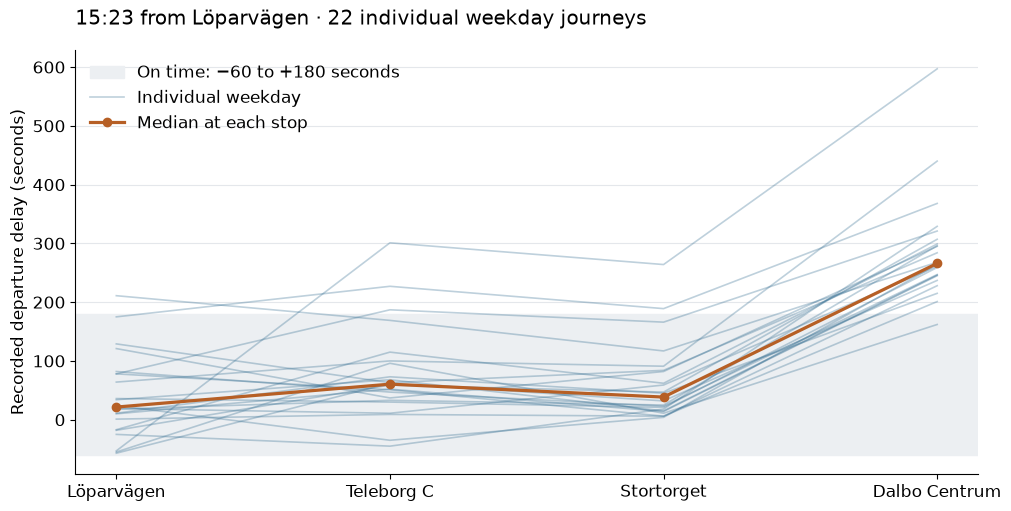

stop_name | observed | eligible | median_delay | on_time
Löparvägen | 22 | 22 | 21.5 | 21
Teleborg C | 22 | 22 | 60.5 | 19
Stortorget | 22 | 22 | 38.5 | 20
Dalbo Centrum | 22 | 22 | 266.0 | 1


In [4]:
journeys = [r for r in results["individual_journeys"] if r["start_seconds"] == 55380]
dates = sorted({r["service_date"] for r in journeys})
assert len(dates) == 22 and len(journeys) == 88
stops = sorted({(r["timing_index"], r["stop_name"]) for r in journeys})
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.axhspan(-60, 180, color="#eceff2", label="On time: −60 to +180 seconds")
for i, date in enumerate(dates):
    day = sorted(
        [r for r in journeys if r["service_date"] == date], key=lambda r: r["timing_index"]
    )
    delays = [r["delay_s"] if r["status"] == "observed" else np.nan for r in day]
    ax.plot(
        range(1, 5),
        delays,
        color=BLUE,
        alpha=0.3,
        linewidth=1.2,
        label="Individual weekday" if i == 0 else None,
    )
profiles = [r for r in results["selected_departure_stops"] if r["start_seconds"] == 55380]
assert all(r["reportable"] for r in profiles)
ax.plot(
    range(1, 5),
    [r["median_delay"] for r in profiles],
    color=ORANGE,
    linewidth=2.3,
    marker="o",
    label="Median at each stop",
)
ax.set_xticks([s[0] for s in stops], [s[1] for s in stops])
ax.set_ylabel("Recorded departure delay (seconds)")
ax.set_title("15:23 from Löparvägen · 22 individual weekday journeys", loc="left", pad=18)
ax.grid(axis="y", color="#e4e7eb")
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
show(fig, "1523-journeys")
table(profiles, ["stop_name", "observed", "eligible", "median_delay", "on_time"])

## 5. Check persistence and measurement limits

Repeated gain does not establish its cause. Daily and leave-one-date-out checks
test whether one date dominates the result; they are not significance tests.
Departures are correlated within trips/dates, so these counts are not independent
statistical samples. First-stop timestamp validation remains a one-day caveat;
no 16-second correction is applied.

In [5]:
daily = results["section_dates"]
omissions = results["leave_one_date_out"]
assert len(daily) == len(omissions) == 22
assert all(
    r["median_change"] > 0 and r["observed_pairs"] >= 20 and r["coverage_pct"] >= 90 for r in daily
)
print(
    "Daily median range:",
    min(r["median_change"] for r in daily),
    "to",
    max(r["median_change"] for r in daily),
    "seconds",
)
print(
    "Leave-one-date-out median range:",
    min(r["median_change"] for r in omissions),
    "to",
    max(r["median_change"] for r in omissions),
    "seconds",
)
table(
    results["linked_recovery"],
    ["start_period", "observed_three_stop_trips", "recovered_then_gained"],
)
print("No timing-stop evidence establishes recovery after Dalbo.")

Daily median range: 94.0 to 152.0 seconds
Leave-one-date-out median range: 123.0 to 125.0 seconds
start_period | observed_three_stop_trips | recovered_then_gained
15:00–17:59 | 358 | 225
Other start times | 973 | 664
No timing-stop evidence establishes recovery after Dalbo.


## Sources and next comparison

Exact setup and result SQL are saved in `data/case-study/city-route1/evidence.json`
and `scripts/sql/city_route1.sql`. Source tables are same-date stop_events, trips,
routes and stops, with the existing route-ID category mapping. Individual exports
stay under ignored `data/`.

[Pinned warehouse](https://huggingface.co/datasets/Traumenteize/kronoberg-transit-punctuality/tree/3cb190163d9c400fd915bd62a919f8f9bfc90dd7)
· [Definitions](../docs/definitions.md) · [Full study](../docs/city-route1-study.md).

Next: study the opposite direction with its own pattern, and repeat over another
complete month before making operational recommendations. No live dashboard,
Sheet, sharing settings or production pipeline definitions were changed.